## install the packages



In [2]:
! pip install scikit-learn==1.6.0 streamlit==1.30.0 pandas==2.0.3 numpy==1.26.4 matplotlib==3.8.2 seaborn==0.12.3 plotly==5.17.0

'pip' is not recognized as an internal or external command,
operable program or batch file.


## import the libraries

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt

print(sns.__version__)



0.13.2


## EDA


In [113]:
df = pd.read_csv("ecommerce.csv")

In [63]:
df.head()

,Customer_ID,Age,Gender,City,Membership_Level,Signup_Date,Days_Since_Signup,Orders_Last_90_Days,Days_Since_Last_Order,Average_Order_Value_AED,...,Email_Open_Rate,Cart_Abandonment_Rate,Payment_Method,Preferred_Category,Average_Delivery_Delay_Days,Loyalty_Points,Subscription_Status,Device_Type,Marketing_Channel,Churn
0,CUST000001,23.0,Male,Fujairah,Basic,10/10/2023,1087,3,24,275.67,...,0.382,0.398,Digital Wallet,Electronics,1.1,1322,No,Mobile,Social Media,0
1,CUST000002,62.0,Male,Ajman,Gold,6/14/2023,1205,5,3,114.72,...,0.272,0.339,Debit Card,Fashion,2.7,333,Yes,Mobile,SMS,0
2,CUST000003,55.0,Male,Dubai,Silver,5/25/2026,129,1,44,132.93,...,0.096,0.337,Credit Card,Grocery,1.4,280,Yes,Desktop,Search,0
3,CUST000004,43.0,Female,Sharjah,Gold,7/16/2024,807,6,40,30.36,...,0.609,0.646,Cash on Delivery,Beauty,1.4,552,No,Mobile,Search,0
4,CUST000005,43.0,Male,Umm Al Quwain,Basic,1/7/2021,2093,1,64,44.02,...,0.710,0.385,Digital Wallet,Sports,1.6,27,No,Mobile,Referral,1


In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200500 entries, 0 to 200499
Data columns (total 27 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Customer_ID                   200500 non-null  object 
 1   Age                           198897 non-null  float64
 2   Gender                        199308 non-null  object 
 3   City                          198095 non-null  object 
 4   Membership_Level              200500 non-null  object 
 5   Signup_Date                   200500 non-null  object 
 6   Days_Since_Signup             200500 non-null  int64  
 7   Orders_Last_90_Days           200500 non-null  int64  
 8   Days_Since_Last_Order         200500 non-null  int64  
 9   Average_Order_Value_AED       198699 non-null  float64
 10  Total_Spend_AED               200500 non-null  float64
 11  Returns_Last_90_Days          200500 non-null  int64  
 12  Discount_Usage_Rate           200500 non-nul

In [65]:
df.isna().sum()

Customer_ID                        0
Age                             1603
Gender                          1192
City                            2405
Membership_Level                   0
Signup_Date                        0
Days_Since_Signup                  0
Orders_Last_90_Days                0
Days_Since_Last_Order              0
Average_Order_Value_AED         1801
Total_Spend_AED                    0
Returns_Last_90_Days               0
Discount_Usage_Rate                0
Support_Tickets_Last_90_Days       0
Complaint_Flag                     0
Website_Visits_Last_30_Days        0
App_Sessions_Last_30_Days          0
Email_Open_Rate                 3006
Cart_Abandonment_Rate              0
Payment_Method                  1409
Preferred_Category                 0
Average_Delivery_Delay_Days     2002
Loyalty_Points                     0
Subscription_Status                0
Device_Type                        0
Marketing_Channel                  0
Churn                              0
d

In [66]:
df.describe()

,Age,Days_Since_Signup,Orders_Last_90_Days,Days_Since_Last_Order,Average_Order_Value_AED,Total_Spend_AED,Returns_Last_90_Days,Discount_Usage_Rate,Support_Tickets_Last_90_Days,Complaint_Flag,Website_Visits_Last_30_Days,App_Sessions_Last_30_Days,Email_Open_Rate,Cart_Abandonment_Rate,Average_Delivery_Delay_Days,Loyalty_Points,Churn
count,198897.000000,200500.000000,200500.000000,200500.000000,198699.000000,200500.000000,200500.000000,200500.000000,200500.000000,200500.000000,200500.000000,200500.000000,197494.000000,200500.000000,198498.000000,200500.000000,200500.000000
mean,46.547494,1113.802279,2.710898,47.848623,110.597499,332.697924,0.244853,0.285168,0.699885,0.078963,7.987267,6.442105,0.383956,0.422484,2.544291,248.978459,0.214364
std,16.918490,625.860090,1.835568,37.772561,1714.759640,386.085228,0.497639,0.159497,0.836919,0.269681,3.475743,3.024622,0.177210,0.198429,2.332906,333.393344,0.410381
min,-5.000000,30.000000,0.000000,-30.000000,-99.000000,3.430000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001000,0.001000,-10.000000,1.000000,0.000000
25%,32.000000,571.000000,1.000000,23.000000,38.940000,108.000000,0.000000,0.161000,0.000000,0.000000,5.000000,4.000000,0.248000,0.268000,1.100000,67.000000,0.000000
50%,47.000000,1112.000000,2.000000,40.000000,60.350000,211.740000,0.000000,0.264000,1.000000,0.000000,8.000000,6.000000,0.372000,0.412000,2.100000,143.000000,0.000000
75%,61.000000,1656.000000,4.000000,64.000000,93.455000,413.732500,0.000000,0.389000,1.000000,0.000000,10.000000,8.000000,0.507000,0.566000,3.400000,302.000000,0.000000
max,150.000000,2199.000000,16.000000,999.000000,100000.000000,20275.050000,5.000000,0.955000,7.000000,1.000000,34.000000,26.000000,0.964000,0.991000,100.000000,23217.000000,1.000000


In [67]:
df = df[['Churn',
         'Days_Since_Last_Order',
         'Orders_Last_90_Days',
         'Website_Visits_Last_30_Days',
         'App_Sessions_Last_30_Days',
         'Total_Spend_AED',
         'Complaint_Flag',
         'Cart_Abandonment_Rate',
         'Support_Tickets_Last_90_Days',
         'Email_Open_Rate',
         'Membership_Level',
         'Subscription_Status',
         'Returns_Last_90_Days']]

df.head()

,Churn,Days_Since_Last_Order,Orders_Last_90_Days,Website_Visits_Last_30_Days,App_Sessions_Last_30_Days,Total_Spend_AED,Complaint_Flag,Cart_Abandonment_Rate,Support_Tickets_Last_90_Days,Email_Open_Rate,Membership_Level,Subscription_Status,Returns_Last_90_Days
0,0,24,3,5,11,1463.78,0,0.398,0,0.382,Basic,No,1
1,0,3,5,11,6,735.15,0,0.339,0,0.272,Gold,Yes,0
2,0,44,1,8,4,308.84,0,0.337,0,0.096,Silver,Yes,0
3,0,40,6,15,7,451.23,0,0.646,0,0.609,Gold,No,1
4,1,64,1,8,2,51.00,0,0.385,0,0.710,Basic,No,0


In [68]:
df_new = df.copy()

## clean the data

In [69]:
df_new.isna().sum()

Churn                              0
Days_Since_Last_Order              0
Orders_Last_90_Days                0
Website_Visits_Last_30_Days        0
App_Sessions_Last_30_Days          0
Total_Spend_AED                    0
Complaint_Flag                     0
Cart_Abandonment_Rate              0
Support_Tickets_Last_90_Days       0
Email_Open_Rate                 3006
Membership_Level                   0
Subscription_Status                0
Returns_Last_90_Days               0
dtype: int64

In [70]:
df_new['Email_Open_Rate'].fillna(df_new['Email_Open_Rate'].median(), inplace=True)

C:\Users\m7779\AppData\Local\Temp\ipykernel_26288\1094117582.py:1: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.





In [71]:
df_new.isna().sum()

Churn                           0
Days_Since_Last_Order           0
Orders_Last_90_Days             0
Website_Visits_Last_30_Days     0
App_Sessions_Last_30_Days       0
Total_Spend_AED                 0
Complaint_Flag                  0
Cart_Abandonment_Rate           0
Support_Tickets_Last_90_Days    0
Email_Open_Rate                 0
Membership_Level                0
Subscription_Status             0
Returns_Last_90_Days            0
dtype: int64

In [ ]:
sns.pairplot(df_new, hue='Churn', palette='Set1')

KeyboardInterrupt: 

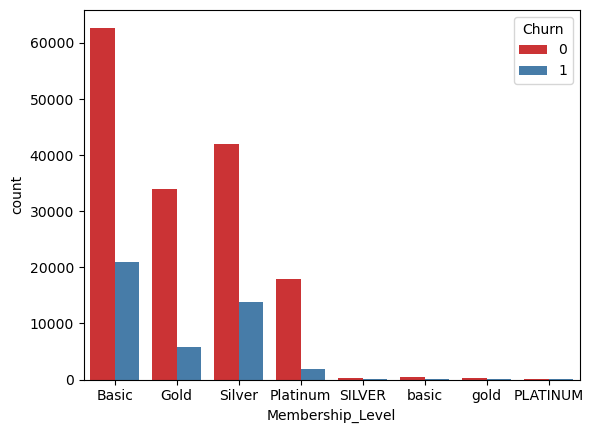

In [72]:
sns.countplot(x='Membership_Level', hue='Churn', data=df_new, palette='Set1')
plt.show()

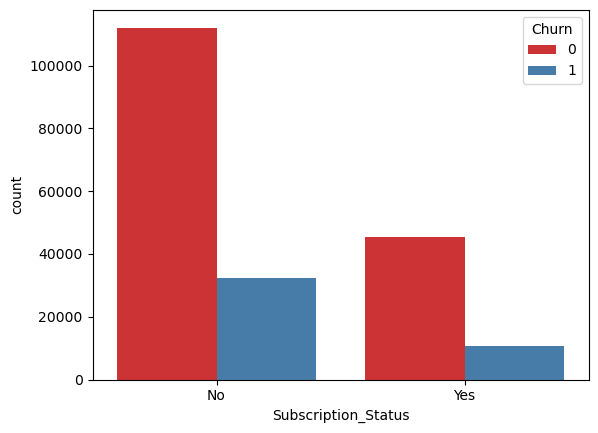

In [73]:
sns.countplot(x='Subscription_Status', hue='Churn', data=df_new, palette='Set1')
plt.show()  

In [74]:
px.histogram(df_new, x='Total_Spend_AED', color='Churn',
             marginal='box', nbins=30,
             title='Total Customer Spending Distribution by Churn')

## split input and output


In [75]:
X = df_new.drop('Churn', axis=1)
y = df_new['Churn']

In [76]:
X

,Days_Since_Last_Order,Orders_Last_90_Days,Website_Visits_Last_30_Days,App_Sessions_Last_30_Days,Total_Spend_AED,Complaint_Flag,Cart_Abandonment_Rate,Support_Tickets_Last_90_Days,Email_Open_Rate,Membership_Level,Subscription_Status,Returns_Last_90_Days
0,24,3,5,11,1463.78,0,0.398,0,0.382,Basic,No,1
1,3,5,11,6,735.15,0,0.339,0,0.272,Gold,Yes,0
2,44,1,8,4,308.84,0,0.337,0,0.096,Silver,Yes,0
3,40,6,15,7,451.23,0,0.646,0,0.609,Gold,No,1
4,64,1,8,2,51.00,0,0.385,0,0.710,Basic,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...
200495,41,5,9,10,240.05,0,0.615,0,0.497,Gold,Yes,0
200496,67,3,11,3,291.30,0,0.658,1,0.224,Gold,Yes,1
200497,94,0,3,6,64.91,0,0.801,0,0.083,Basic,No,0
200498,34,2,10,5,181.50,0,0.152,0,0.869,Basic,No,0


In [77]:
X['Membership_Level'].value_counts()

Membership_Level
Basic       83777
Silver      55875
Gold        39726
Platinum    19821
basic         542
SILVER        380
gold          235
PLATINUM      144
Name: count, dtype: int64

In [78]:
X = pd.get_dummies(
    X,
    columns=['Membership_Level','Subscription_Status'],
    drop_first=True, dtype=int
)


In [79]:
X

,Days_Since_Last_Order,Orders_Last_90_Days,Website_Visits_Last_30_Days,App_Sessions_Last_30_Days,Total_Spend_AED,Complaint_Flag,Cart_Abandonment_Rate,Support_Tickets_Last_90_Days,Email_Open_Rate,Returns_Last_90_Days,Membership_Level_Gold,Membership_Level_PLATINUM,Membership_Level_Platinum,Membership_Level_SILVER,Membership_Level_Silver,Membership_Level_basic,Membership_Level_gold,Subscription_Status_Yes
0,24,3,5,11,1463.78,0,0.398,0,0.382,1,0,0,0,0,0,0,0,0
1,3,5,11,6,735.15,0,0.339,0,0.272,0,1,0,0,0,0,0,0,1
2,44,1,8,4,308.84,0,0.337,0,0.096,0,0,0,0,0,1,0,0,1
3,40,6,15,7,451.23,0,0.646,0,0.609,1,1,0,0,0,0,0,0,0
4,64,1,8,2,51.00,0,0.385,0,0.710,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200495,41,5,9,10,240.05,0,0.615,0,0.497,0,1,0,0,0,0,0,0,1
200496,67,3,11,3,291.30,0,0.658,1,0.224,1,1,0,0,0,0,0,0,1
200497,94,0,3,6,64.91,0,0.801,0,0.083,0,0,0,0,0,0,0,0,0
200498,34,2,10,5,181.50,0,0.152,0,0.869,0,0,0,0,0,0,0,0,0


## split the data into train and test

In [80]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Apply Scaling

In [81]:
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

## Apply the modeling 

In [82]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
lr = LogisticRegression(random_state=42)
lr.fit(X_train_scaled, y_train)
y_pred = lr.predict(X_test_scaled)
print("Classification report training:\n",
      classification_report(y_train, lr.predict(X_train_scaled)))
print("Classification report testing:\n",
      classification_report(y_test, y_pred))

Classification report training:
               precision    recall  f1-score   support

           0       0.82      0.97      0.89    126028
           1       0.65      0.22      0.33     34372

    accuracy                           0.81    160400
   macro avg       0.74      0.60      0.61    160400
weighted avg       0.78      0.81      0.77    160400

Classification report testing:
               precision    recall  f1-score   support

           0       0.82      0.97      0.89     31492
           1       0.65      0.23      0.33      8608

    accuracy                           0.81     40100
   macro avg       0.73      0.60      0.61     40100
weighted avg       0.78      0.81      0.77     40100



In [83]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

print("Classification report training:\n",
      classification_report(y_train, knn.predict(X_train_scaled)))

print("Classification report testing:\n",
      classification_report(y_test, y_pred))

Classification report training:
               precision    recall  f1-score   support

           0       0.85      0.96      0.90    126028
           1       0.71      0.40      0.51     34372

    accuracy                           0.84    160400
   macro avg       0.78      0.68      0.71    160400
weighted avg       0.82      0.84      0.82    160400

Classification report testing:
               precision    recall  f1-score   support

           0       0.82      0.92      0.87     31492
           1       0.47      0.26      0.33      8608

    accuracy                           0.78     40100
   macro avg       0.64      0.59      0.60     40100
weighted avg       0.74      0.78      0.75     40100



In [84]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=42, max_depth=5)
dt.fit(X_train_scaled, y_train)
y_pred = dt.predict(X_test_scaled)

print("Classification report training:\n",
      classification_report(y_train, dt.predict(X_train_scaled)))

print("Classification report testing:\n",
      classification_report(y_test, y_pred))

Classification report training:
               precision    recall  f1-score   support

           0       0.82      0.97      0.89    126028
           1       0.63      0.20      0.30     34372

    accuracy                           0.80    160400
   macro avg       0.72      0.58      0.59    160400
weighted avg       0.78      0.80      0.76    160400

Classification report testing:
               precision    recall  f1-score   support

           0       0.82      0.97      0.88     31492
           1       0.61      0.20      0.30      8608

    accuracy                           0.80     40100
   macro avg       0.71      0.58      0.59     40100
weighted avg       0.77      0.80      0.76     40100



In [85]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    max_depth=5
)
rf.fit(X_train_scaled, y_train)
y_pred = rf.predict(X_test_scaled)

print("Classification report training:\n",
      classification_report(y_train, rf.predict(X_train_scaled)))

print("Classification report testing:\n",
      classification_report(y_test, y_pred))

Classification report training:
               precision    recall  f1-score   support

           0       0.79      1.00      0.88    126028
           1       0.79      0.06      0.10     34372

    accuracy                           0.79    160400
   macro avg       0.79      0.53      0.49    160400
weighted avg       0.79      0.79      0.72    160400

Classification report testing:
               precision    recall  f1-score   support

           0       0.79      1.00      0.88     31492
           1       0.79      0.06      0.11      8608

    accuracy                           0.79     40100
   macro avg       0.79      0.53      0.49     40100
weighted avg       0.79      0.79      0.72     40100



## cross validation

In [86]:
from sklearn.model_selection import KFold, cross_validate
kf = KFold(n_splits=10, shuffle=True, random_state=42)
scores = cross_validate(rf, X_train_scaled, y_train, cv=kf, return_train_score=True)
scores

{'fit_time': array([8.67491293, 8.96990395, 8.90903997, 8.77145529, 8.16276145,
        8.5807333 , 8.89308405, 8.53435516, 8.66782427, 8.28149652]),
 'score_time': array([0.08237386, 0.09254408, 0.09956813, 0.08950949, 0.07457566,
        0.06700778, 0.07250643, 0.08051491, 0.08051682, 0.0805347 ]),
 'test_score': array([0.79501247, 0.79569825, 0.79438903, 0.78952618, 0.79476309,
        0.79239401, 0.7861596 , 0.79501247, 0.79794264, 0.79413965]),
 'train_score': array([0.79409116, 0.79380022, 0.79470075, 0.79465919, 0.79336381,
        0.79447215, 0.79481158, 0.79396647, 0.79294126, 0.79395262])}

##  hyper parameter tuning

In [87]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy'
)

grid_search.fit(X_train_scaled, y_train)


GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [3, 5, 7],
                         'n_estimators': [50, 100, 200]},
             scoring='accuracy')

In [88]:
grid_search.best_params_

{'max_depth': 7, 'n_estimators': 200}

In [90]:
rf = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=5)
rf.fit(X_train_scaled, y_train)
y_pred = rf.predict(X_test_scaled)
print("classification report training:\n", classification_report(y_train, rf.predict(X_train_scaled)))

print("Classification report testing:\n", classification_report(y_test, y_pred))


classification report training:
               precision    recall  f1-score   support

           0       0.79      1.00      0.88    126028
           1       0.79      0.06      0.10     34372

    accuracy                           0.79    160400
   macro avg       0.79      0.53      0.49    160400
weighted avg       0.79      0.79      0.72    160400

Classification report testing:
               precision    recall  f1-score   support

           0       0.79      1.00      0.88     31492
           1       0.79      0.06      0.11      8608

    accuracy                           0.79     40100
   macro avg       0.79      0.53      0.49     40100
weighted avg       0.79      0.79      0.72     40100



## create the pipeline for deployment

In [91]:
df

,Churn,Days_Since_Last_Order,Orders_Last_90_Days,Website_Visits_Last_30_Days,App_Sessions_Last_30_Days,Total_Spend_AED,Complaint_Flag,Cart_Abandonment_Rate,Support_Tickets_Last_90_Days,Email_Open_Rate,Membership_Level,Subscription_Status,Returns_Last_90_Days
0,0,24,3,5,11,1463.78,0,0.398,0,0.382,Basic,No,1
1,0,3,5,11,6,735.15,0,0.339,0,0.272,Gold,Yes,0
2,0,44,1,8,4,308.84,0,0.337,0,0.096,Silver,Yes,0
3,0,40,6,15,7,451.23,0,0.646,0,0.609,Gold,No,1
4,1,64,1,8,2,51.00,0,0.385,0,0.710,Basic,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
200495,0,41,5,9,10,240.05,0,0.615,0,0.497,Gold,Yes,0
200496,0,67,3,11,3,291.30,0,0.658,1,0.224,Gold,Yes,1
200497,0,94,0,3,6,64.91,0,0.801,0,0.083,Basic,No,0
200498,0,34,2,10,5,181.50,0,0.152,0,0.869,Basic,No,0


In [92]:
df.isna().sum()

Churn                              0
Days_Since_Last_Order              0
Orders_Last_90_Days                0
Website_Visits_Last_30_Days        0
App_Sessions_Last_30_Days          0
Total_Spend_AED                    0
Complaint_Flag                     0
Cart_Abandonment_Rate              0
Support_Tickets_Last_90_Days       0
Email_Open_Rate                 3006
Membership_Level                   0
Subscription_Status                0
Returns_Last_90_Days               0
dtype: int64

## split input and output


In [93]:
X = df.drop('Churn', axis=1)
y = df['Churn']

In [94]:
X

,Days_Since_Last_Order,Orders_Last_90_Days,Website_Visits_Last_30_Days,App_Sessions_Last_30_Days,Total_Spend_AED,Complaint_Flag,Cart_Abandonment_Rate,Support_Tickets_Last_90_Days,Email_Open_Rate,Membership_Level,Subscription_Status,Returns_Last_90_Days
0,24,3,5,11,1463.78,0,0.398,0,0.382,Basic,No,1
1,3,5,11,6,735.15,0,0.339,0,0.272,Gold,Yes,0
2,44,1,8,4,308.84,0,0.337,0,0.096,Silver,Yes,0
3,40,6,15,7,451.23,0,0.646,0,0.609,Gold,No,1
4,64,1,8,2,51.00,0,0.385,0,0.710,Basic,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...
200495,41,5,9,10,240.05,0,0.615,0,0.497,Gold,Yes,0
200496,67,3,11,3,291.30,0,0.658,1,0.224,Gold,Yes,1
200497,94,0,3,6,64.91,0,0.801,0,0.083,Basic,No,0
200498,34,2,10,5,181.50,0,0.152,0,0.869,Basic,No,0


In [95]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [96]:
numerical_columns = X_train.select_dtypes(include=['int64', 'float64']).columns
numerical_columns

Index(['Days_Since_Last_Order', 'Orders_Last_90_Days',
       'Website_Visits_Last_30_Days', 'App_Sessions_Last_30_Days',
       'Total_Spend_AED', 'Complaint_Flag', 'Cart_Abandonment_Rate',
       'Support_Tickets_Last_90_Days', 'Email_Open_Rate',
       'Returns_Last_90_Days'],
      dtype='object')

In [97]:
cat_columns = X_train.select_dtypes(include=['object', 'category']).columns
cat_columns

Index(['Membership_Level', 'Subscription_Status'], dtype='object')

In [98]:
X_train['Membership_Level'].unique()


array(['Basic', 'Silver', 'Platinum', 'Gold', 'basic', 'PLATINUM', 'gold',
       'SILVER'], dtype=object)

In [99]:
X_train['Subscription_Status'].unique()


array(['Yes', 'No'], dtype=object)

In [100]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler(with_mean=False))
])
numerical_pipeline

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler(with_mean=False))])

In [101]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first'))
])

cat_pipeline

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(drop='first'))])

In [102]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_columns),
    ('cat', cat_pipeline, cat_columns)
], remainder='passthrough')

preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler',
                                                  StandardScaler(with_mean=False))]),
                                 Index(['Days_Since_Last_Order', 'Orders_Last_90_Days',
       'Website_Visits_Last_30_Days', 'App_Sessions_Last_30_Days',
       'Total_Spend_AED', 'Complaint_Flag', 'Cart_Abandonment_Rate',
       'Support_Tickets_Last_90_Days', 'Email_Open_Rate',
       'Returns_Last_90_Days'],
      dtype='object')),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(drop='first'))]),
                                 Index(['Membership_Level', 'Subscription_Status'], dtype='object'))])

In [103]:
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('rf', RandomForestClassifier(random_state=42, n_estimators=100, max_depth=5))
])

final_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler(with_mean=False))]),
                                                  Index(['Days_Since_Last_Order', 'Orders_Last_90_Days',
       'Website_Visits_Last_30_Days', 'App_Sessions_Last_30_Days',
       'Total_Spend_AED', 'Complaint_Flag', 'Ca...ndonment_Rate',
       'Support_Tickets_Last_90_Days', 'Email_Open_Rate',
       'Returns_Last_90_Days'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(drop='first'))]),
                                                  Index(['Membership_Level', 'Subscription_Status'], dtype='object'))])),
                ('rf', RandomForestClassifier(max_depth=5, random_state=42))])

In [104]:
X_train

,Days_Since_Last_Order,Orders_Last_90_Days,Website_Visits_Last_30_Days,App_Sessions_Last_30_Days,Total_Spend_AED,Complaint_Flag,Cart_Abandonment_Rate,Support_Tickets_Last_90_Days,Email_Open_Rate,Membership_Level,Subscription_Status,Returns_Last_90_Days
110431,70,1,6,6,56.05,1,0.535,1,0.560,Basic,Yes,0
10891,8,1,4,5,210.34,0,0.477,0,0.436,Silver,Yes,0
135402,45,2,6,3,332.38,0,0.558,0,NaN,Silver,No,1
72253,28,1,8,8,98.22,0,0.079,0,0.359,Basic,Yes,0
193943,4,3,7,5,225.65,0,0.581,0,0.238,Platinum,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...
119879,68,3,9,3,697.63,0,0.028,0,0.677,Silver,No,0
103694,38,2,8,15,335.92,0,0.273,0,0.235,Gold,No,0
131932,57,5,13,7,883.83,1,0.562,2,0.051,Basic,No,0
146867,19,6,4,8,799.54,0,0.708,1,0.811,Basic,No,2


In [105]:
final_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler(with_mean=False))]),
                                                  Index(['Days_Since_Last_Order', 'Orders_Last_90_Days',
       'Website_Visits_Last_30_Days', 'App_Sessions_Last_30_Days',
       'Total_Spend_AED', 'Complaint_Flag', 'Ca...ndonment_Rate',
       'Support_Tickets_Last_90_Days', 'Email_Open_Rate',
       'Returns_Last_90_Days'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(drop='first'))]),
                                                  Index(['Membership_Level', 'Subscription_Status'], dtype='object'))])),
                ('rf', RandomForestClassifier(max_depth=5, random_state=42))])

In [106]:
y_pred = final_pipeline.predict(X_test)
y_pred

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

In [108]:
import joblib
joblib.dump(final_pipeline, 'churn_model.pkl')

['churn_model.pkl']

In [109]:
classifier = joblib.load('churn_model.pkl')

In [112]:
classifier.predict(pd.DataFrame([{
    'Days_Since_Last_Order': 15,
    'Orders_Last_90_Days': 5,
    'Website_Visits_Last_30_Days': 20,
    'App_Sessions_Last_30_Days': 30,
    'Total_Spend_AED': 1500,
    'Complaint_Flag': 0,
    'Cart_Abandonment_Rate': 0.25,
    'Support_Tickets_Last_90_Days': 1,
    'Email_Open_Rate': 0.60,
    'Membership_Level': 'Gold',
    'Subscription_Status': 'Yes',
    'Returns_Last_90_Days': 0
}]))


array([0], dtype=int64)

In [118]:

%%writefile app.py

import streamlit as st
import joblib
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import numpy as np

classifier = joblib.load('churn_model.pkl')

def predict_churn(
    Days_Since_Last_Order,
    Orders_Last_90_Days,
    Website_Visits_Last_30_Days,
    App_Sessions_Last_30_Days,
    Total_Spend_AED,
    Complaint_Flag,
    Cart_Abandonment_Rate,
    Support_Tickets_Last_90_Days,
    Email_Open_Rate,
    Membership_Level,
    Subscription_Status,
    Returns_Last_90_Days
):
    input_data = pd.DataFrame([{
        'Days_Since_Last_Order': Days_Since_Last_Order,
        'Orders_Last_90_Days': Orders_Last_90_Days,
        'Website_Visits_Last_30_Days': Website_Visits_Last_30_Days,
        'App_Sessions_Last_30_Days': App_Sessions_Last_30_Days,
        'Total_Spend_AED': Total_Spend_AED,
        'Complaint_Flag': Complaint_Flag,
        'Cart_Abandonment_Rate': Cart_Abandonment_Rate,
        'Support_Tickets_Last_90_Days': Support_Tickets_Last_90_Days,
        'Email_Open_Rate': Email_Open_Rate,
        'Membership_Level': Membership_Level,
        'Subscription_Status': Subscription_Status,
        'Returns_Last_90_Days': Returns_Last_90_Days
    }])

    prediction = classifier.predict(input_data)
    label = 'Will Churn' if prediction[0] == 1 else 'Will Not Churn'
    return label

def main():
    st.title("Customer Churn Prediction")
    html_temp = """
        <div style="background-color:red">
            <h2 style="color:white;text-align:center;">This our Streamlit Deployment App</h2>
        </div>
        """
    st.write("Enter customer details to predict churn probability.")

    Days_Since_Last_Order = st.number_input("Days Since Last Order", min_value=0)
    Orders_Last_90_Days = st.number_input("Orders in Last 90 Days", min_value=0)
    Website_Visits_Last_30_Days = st.number_input("Website Visits in Last 30 Days", min_value=0)
    App_Sessions_Last_30_Days = st.number_input("App Sessions in Last 30 Days", min_value=0)
    Total_Spend_AED = st.number_input("Total Spend (AED)", min_value=0.0, format="%.2f")
    Complaint_Flag = st.selectbox("Complaint Flag", [0, 1])
    Cart_Abandonment_Rate = st.slider("Cart Abandonment Rate", 0.0, 1.0, step=0.01)
    Support_Tickets_Last_90_Days = st.number_input("Support Tickets in Last 90 Days", min_value=0)
    Email_Open_Rate = st.slider("Email Open Rate", 0.0, 1.0, step=0.01)
    Membership_Level = st.selectbox("Membership Level", ['Bronze', 'Silver', 'Gold', 'Platinum'])
    Subscription_Status = st.selectbox("Subscription Status", ['Yes', 'No'])
    Returns_Last_90_Days = st.number_input("Returns in Last 90 Days", min_value=0)

    if st.button("Predict Churn"):
        result = predict_churn(
            Days_Since_Last_Order,
            Orders_Last_90_Days,
            Website_Visits_Last_30_Days,
            App_Sessions_Last_30_Days,
            Total_Spend_AED,
            Complaint_Flag,
            Cart_Abandonment_Rate,
            Support_Tickets_Last_90_Days,
            Email_Open_Rate,
            Membership_Level,
            Subscription_Status,
            Returns_Last_90_Days
        )
        st.success(f"Prediction: {result}")

if __name__ == '__main__':
    main()
    


Overwriting app.py
